# Opportunity prediction before execution

Rank events from scheduled snapshots, then monitor the top N for the next window. This first layer compares opportunity **occurrence** and **quoted dollar magnitude**. It does not learn execution losses or run economic replay.

The dollar target is the largest qualifying one-basket margin observed within the following hour. It is an opportunity-size proxy, **not total hourly profit**. Repeated snapshots and overlapping pairs are not added. All final-test data from 8 January 2026 remain closed.

See [the research report](../docs/reports/opportunity_prediction.md) and [dataset definitions](../docs/dataset.md).

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.paths import PROCESSED_DIR
from src.reporting.workflow import profitability_dataset
from src.data.opportunities import build_dataset as build_occurrence, load_dataset
from src.data.opportunity_value import build_dataset as build_value
from src.models.opportunities import train_study as train_occurrence
from src.models.opportunity_value import train_study as train_value
from src.reporting.opportunities import build_report as report_occurrence, verify as verify_occurrence
from src.reporting.opportunity_value import build_report as report_value, verify as verify_value

# A nonempty suffix creates a separate reproducible run; completed outputs are never overwritten.
RUN_TAG = ''
OBS_DATA = PROCESSED_DIR / f'opportunities{RUN_TAG}'
VALUE_DATA = PROCESSED_DIR / f'opportunity_value{RUN_TAG}'
OBS_RUN = ROOT / 'results' / f'opportunities{RUN_TAG}'
VALUE_RUN = ROOT / 'results' / f'opportunity_value{RUN_TAG}'
REBUILD_DATA = False
RETRAIN = False
REBUILD_REPORTS = False
pd.set_option('display.max_colwidth', 95)

## Rebuild controls and integrity

Rebuilding labels uses saved raw Dome histories and the frozen scheduled features. Set a new `RUN_TAG` before enabling rebuild/training. The occurrence study fits 192 inner candidates and 36 outer models. The value study fits another 288 inner candidates and 36 outer models. Tuned parameters use inner chronological validation only; fixed configurations remain controls.

Reports verify hashes, temporal separation, actual selected parameters and serialized model input columns. The final lockbox is never read.

In [2]:
if REBUILD_DATA:
    build_occurrence(OBS_DATA, profitability_dataset())
    build_value(VALUE_DATA, OBS_DATA)
if RETRAIN:
    with threadpool_limits(limits=4):
        train_occurrence(OBS_RUN, OBS_DATA)
        train_value(VALUE_RUN, VALUE_DATA, OBS_RUN, OBS_DATA)
if REBUILD_REPORTS:
    report_occurrence(OBS_RUN, OBS_DATA)
    report_value(VALUE_RUN, VALUE_DATA, OBS_RUN, OBS_DATA)
verify_occurrence(OBS_RUN, OBS_DATA)
verify_value(VALUE_RUN, VALUE_DATA, OBS_RUN, OBS_DATA)
print('Verified: observation-only labels, chronological tuning, fitted feature schemas, unchanged comparators and closed final test.')

Verified: observation-only labels, chronological tuning, fitted feature schemas, unchanged comparators and closed final test.


## Training rows and label audit

One row is one event at a scheduled scan. Only the 33 `x_` inputs and, in combined models, three metadata fields are predictors. Current quoted margin, its previous scheduled value and its change remain features. `target`, `value_target`, coverage and future witness columns are **not** features.

Unknown windows consume ranking slots and are excluded from fitting and metric denominators. A witnessed gap in an incomplete window does not become a positive training label. A brief opportunity counts even when a later execution simulation would lose money.

In [3]:
examples = load_dataset(VALUE_DATA)
counts = pd.read_csv(OBS_RUN / 'analysis/label_counts.csv')
display(counts)
display(pd.read_csv(OBS_RUN / 'analysis/label_transition.csv'))
display(pd.read_csv(VALUE_RUN / 'analysis/value_distribution.csv'))
columns = ['event_slug', 'time', 'x_best_quoted_net_usd', 'x_ask_depth_sum',
           'x_book_age_max_s', 'label_known', 'target', 'value_target']
display(examples.loc[examples.target.eq(1), columns].head(8))
print('Positive labels:', int(examples.target.eq(1).sum()),
      '| Unknown labels:', int((~examples.label_known).sum()))

,population,events,rows,known,positive,negative,unknown,positive_at_scan,observed_new_onset,new_onset_without_scan,witnessed_unknown
0,development,48,26835,21827,454,21373,5008,185,304,269,75
1,outer_evaluation,44,20951,16957,385,16572,3994,152,265,233,75


,old_label,new_label,rows
0,negative,negative,21373
1,negative,positive,10
2,positive,positive,444
3,unknown,unknown,5008


,population,known,positive,median_positive_peak,p90_positive_peak,largest_peak,sum_hourly_peaks,december_fed_share
0,development,21827,454,0.90917,59.15275,1366.79882,9465.05113,0.782340
1,outer_evaluation,16957,385,1.16800,66.86620,1366.79882,8915.83999,0.828301


,event_slug,time,x_best_quoted_net_usd,x_ask_depth_sum,x_book_age_max_s,label_known,target,value_target
23,world-series-champion-2025,2025-10-15 00:00:00+00:00,-1.550000e-01,38225564.43,1040.316,True,1.0,1.46217
50,fed-decision-in-october,2025-10-15 04:00:00+00:00,-4.000000e-02,31110533.40,404.457,True,1.0,0.40000
60,fed-decision-in-october,2025-10-15 05:00:00+00:00,-7.000000e-02,30955400.50,603.026,True,1.0,1.71200
71,fed-decision-in-october,2025-10-15 06:00:00+00:00,7.127000e-01,41221992.68,208.122,True,1.0,0.71200
166,fed-decision-in-october,2025-10-15 14:00:00+00:00,-2.500000e-02,41642792.99,147.910,True,1.0,2.97200
178,fed-decision-in-october,2025-10-15 15:00:00+00:00,4.547474e-13,41393981.71,210.135,True,1.0,12.53400
220,which-party-holds-the-most-seats-after-argentina-deputies-election,2025-10-15 18:00:00+00:00,-1.150000e-01,884201.75,15945.783,True,1.0,2.44286
902,where-will-trump-and-putin-meet-next-393,2025-10-17 19:00:00+00:00,-2.850000e-01,397323.73,176373.503,True,1.0,2.18386


Positive labels: 454 | Unknown labels: 5008


## Matched model comparison

Classifiers tune **recall@5**. Direct and two-stage value models tune **captured peak quoted value@5**. Two-stage scores multiply an unweighted opportunity gate by conditional expected value; they have no hard gate threshold. Ensembles use equal rank averages for classifiers and equal dollar-prediction averages for value models.

Recall gives every known positive hour equal weight. Value capture weights it by its peak displayed margin. The sum of those maxima is not a sum of executable profits. A model can improve one measure while worsening the other. Scores from class-weighted classifiers are not assumed calibrated probabilities.

In [4]:
metrics = pd.read_csv(VALUE_RUN / 'metrics.csv')
comparison = metrics.loc[metrics.scope.eq('all_events') & metrics.fold.eq('all')]
shown = comparison.model.str.startswith('tuned_') | comparison.model.isin([
    'quoted_gap_rule', 'fixed_book_logistic', 'fixed_combined_random_forest', 'depth_rule', 'freshness_rule'])
fields = ['model', 'captured_positive_windows', 'positive_windows', 'recall',
          'peak_value_recall', 'future_recall', 'new_without_scan_recall',
          'precision_known', 'selected_unknown']
for n in [5, 3]:
    print(f'Top {n} monitored events')
    display(comparison.loc[shown & comparison.top_n.eq(n), fields]
            .sort_values('peak_value_recall', ascending=False).round(4))

Top 5 monitored events


,model,captured_positive_windows,positive_windows,recall,peak_value_recall,future_recall,new_without_scan_recall,precision_known,selected_unknown
64,fixed_combined_random_forest,367,385,0.9532,0.9987,0.9321,0.9227,0.0556,1439
184,tuned_combined_rank_ensemble,366,385,0.9506,0.9984,0.9283,0.9185,0.0553,1412
160,tuned_combined_boosted_trees,363,385,0.9429,0.9984,0.9170,0.9056,0.0549,1423
192,tuned_combined_xgboost,364,385,0.9455,0.9980,0.9245,0.9142,0.0554,1464
144,freshness_rule,343,385,0.8909,0.9952,0.9245,0.9227,0.0433,113
240,tuned_value_two_stage_random_forest,357,385,0.9273,0.9946,0.8943,0.8798,0.0552,1564
16,fixed_book_logistic,376,385,0.9766,0.9943,0.9660,0.9614,0.0497,461
168,tuned_combined_logistic,361,385,0.9377,0.9931,0.9094,0.8970,0.0519,1074
176,tuned_combined_random_forest,361,385,0.9377,0.9910,0.9094,0.8970,0.0556,1536
200,tuned_value_ensemble,349,385,0.9065,0.9896,0.8642,0.8455,0.0534,1493


Top 3 monitored events


,model,captured_positive_windows,positive_windows,recall,peak_value_recall,future_recall,new_without_scan_recall,precision_known,selected_unknown
17,fixed_book_logistic,342,385,0.8883,0.9807,0.8491,0.8283,0.0716,117
65,fixed_combined_random_forest,334,385,0.8675,0.9776,0.8113,0.7854,0.0786,644
145,freshness_rule,264,385,0.6857,0.9466,0.7623,0.7639,0.0541,19
193,tuned_combined_xgboost,308,385,0.8000,0.9400,0.7170,0.6781,0.0819,1134
177,tuned_combined_random_forest,321,385,0.8338,0.9309,0.7585,0.7253,0.0831,1034
1,depth_rule,182,385,0.4727,0.9107,0.5208,0.5193,0.0431,675
233,tuned_value_two_stage_boosted_trees,227,385,0.5896,0.8910,0.5396,0.5193,0.0561,850
185,tuned_combined_rank_ensemble,320,385,0.8312,0.8787,0.7547,0.7210,0.0834,1061
161,tuned_combined_boosted_trees,311,385,0.8078,0.7510,0.7208,0.6824,0.0829,1146
201,tuned_value_ensemble,292,385,0.7584,0.7317,0.6491,0.6009,0.0765,1081


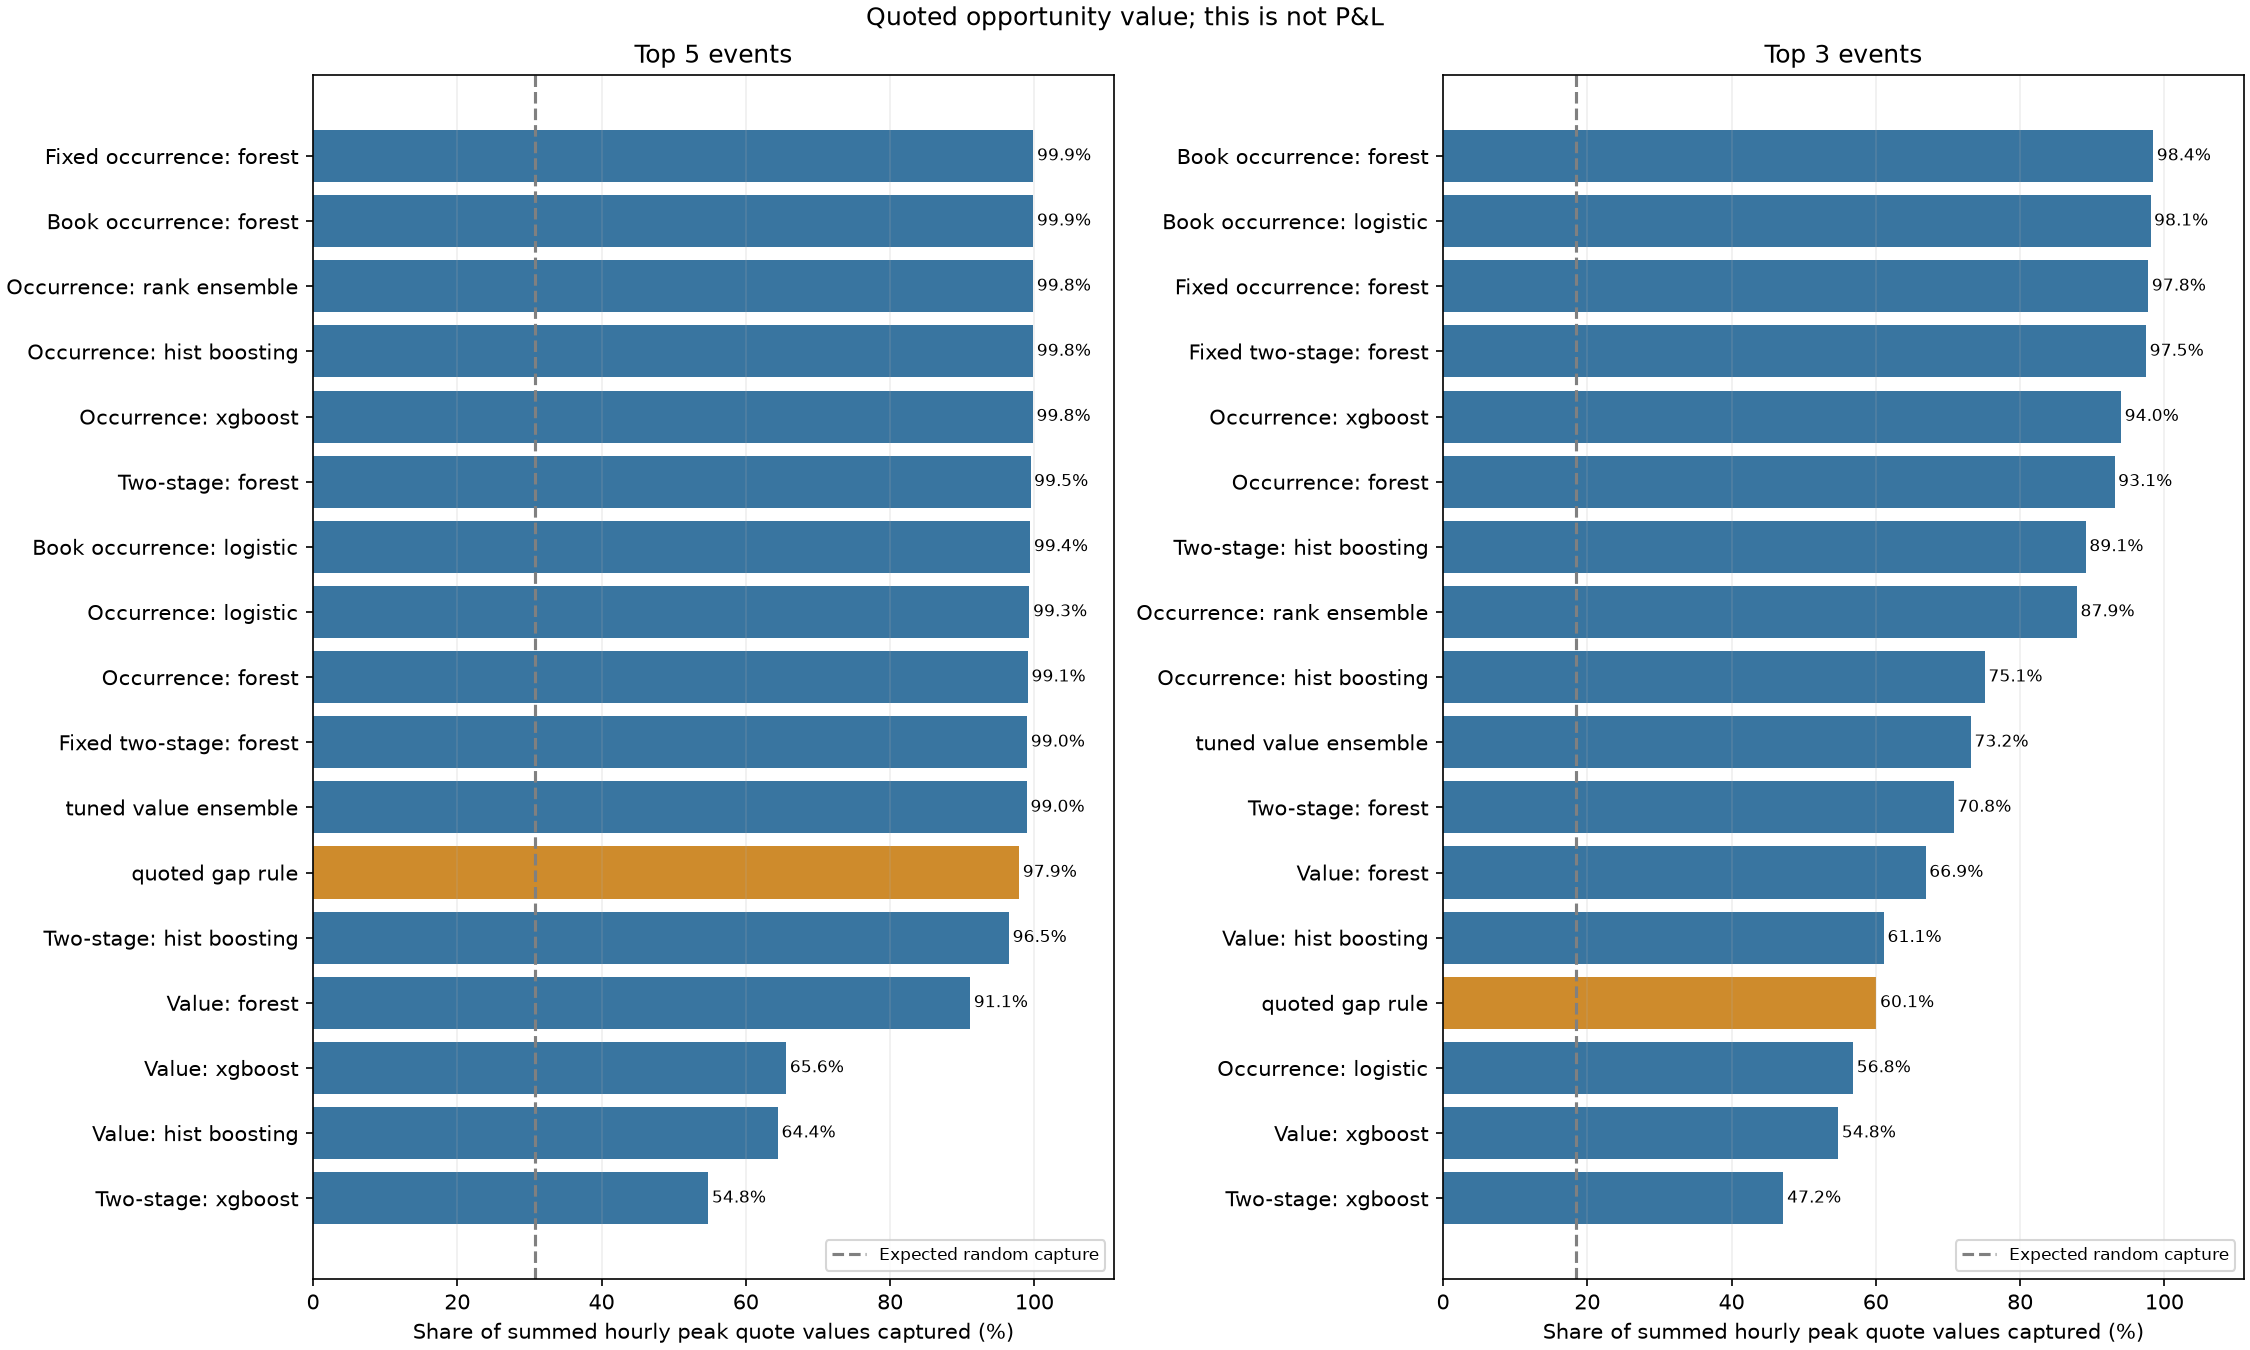

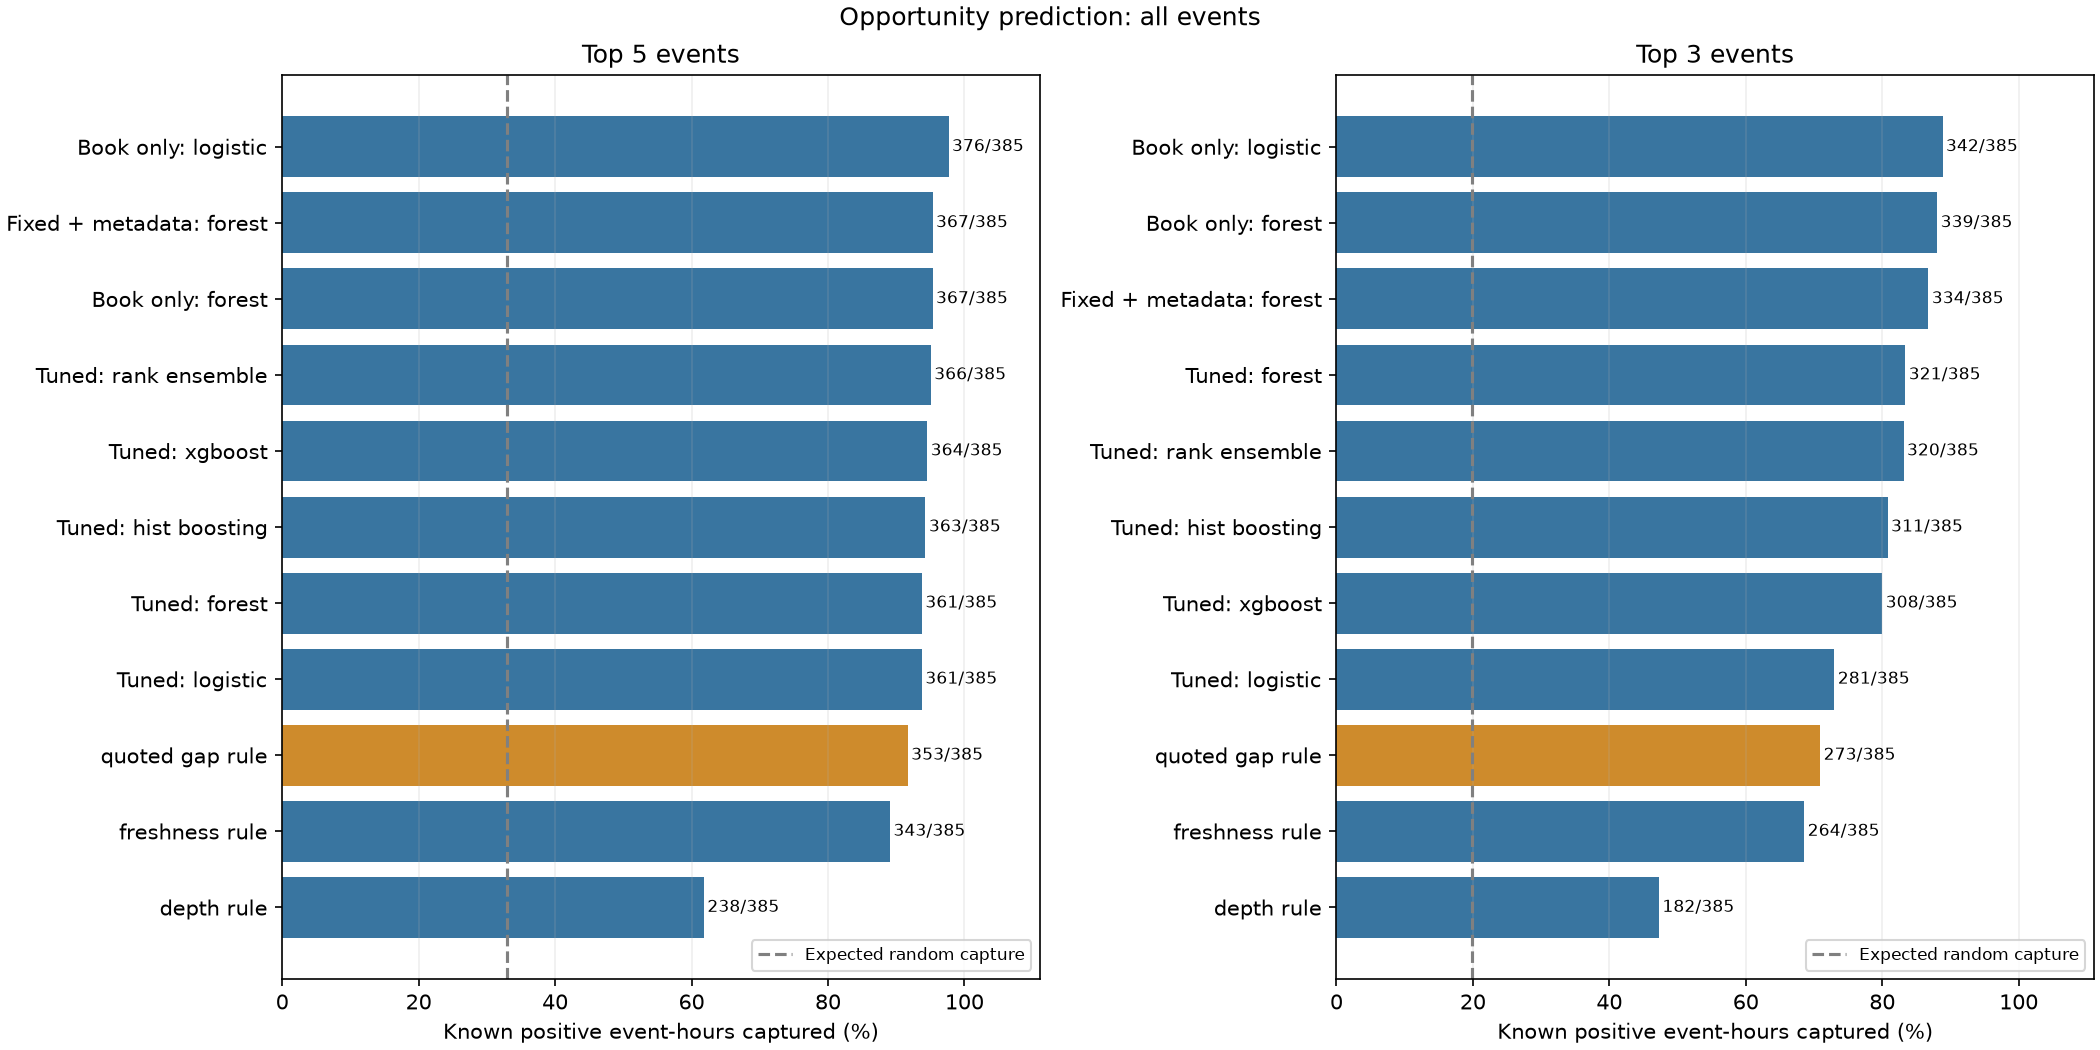

In [5]:
display(Image(filename=str(VALUE_RUN / 'analysis/all_events.png')))
display(Image(filename=str(OBS_RUN / 'analysis/all_events.png')))

## Chronological stability, concentration and limited budget

The same fitted predictions are ranked at N=5 and N=3. Removing December Fed reranks the remaining pool; it is not a new fit or an unseen-topic experiment. Per-group attribution below selects events from the **whole pool first**, then measures what was captured within each stratum.

Paired intervals resample the nine event families, preserving each policy's actual selections. They are exploratory, use few clusters, do not correct for trying many models, and are not a replacement for the final test.

In [6]:
focus = ['quoted_gap_rule', 'fixed_book_logistic', 'tuned_combined_xgboost',
         'tuned_value_regression_random_forest', 'tuned_value_two_stage_random_forest',
         'tuned_value_ensemble']
display(metrics.loc[metrics.scope.eq('all_events') & metrics.fold.ne('all') &
                    metrics.top_n.eq(5) & metrics.model.isin(focus),
                    ['fold'] + fields].round(4))
display(metrics.loc[metrics.scope.eq('exclude_december_fed') & metrics.fold.eq('all') &
                    metrics.model.isin(focus), ['top_n'] + fields].round(4))
groups = pd.read_csv(VALUE_RUN / 'analysis/group_capture.csv')
display(groups.loc[groups.group_type.eq('stratum') & groups.top_n.eq(5) & groups.model.isin(focus)])
intervals = pd.read_csv(VALUE_RUN / 'analysis/paired_value_intervals.csv')
display(intervals.loc[intervals.model.isin(focus)].round(4))
novel = pd.read_csv(VALUE_RUN / 'analysis/new_opportunity_value.csv')
print('Observed new opportunities in initially opportunity-free hours')
display(novel.loc[novel.model.isin(focus)].round(4))

,fold,model,captured_positive_windows,positive_windows,recall,peak_value_recall,future_recall,new_without_scan_recall,precision_known,selected_unknown
18,dec_late,fixed_book_logistic,49,49,1.0000,1.0000,1.0000,1.0000,0.0189,155
20,nov_early,fixed_book_logistic,160,165,0.9697,0.9925,0.9550,0.9495,0.0716,286
22,nov_late,fixed_book_logistic,167,171,0.9766,0.9989,0.9655,0.9604,0.0609,20
154,dec_late,quoted_gap_rule,49,49,1.0000,1.0000,1.0000,1.0000,0.0184,92
156,nov_early,quoted_gap_rule,146,165,0.8848,0.9878,0.8288,0.8081,0.0922,936
158,nov_late,quoted_gap_rule,158,171,0.9240,0.9436,0.8879,0.8713,0.0696,490
194,dec_late,tuned_combined_xgboost,49,49,1.0000,1.0000,1.0000,1.0000,0.0189,168
196,nov_early,tuned_combined_xgboost,150,165,0.9091,0.9976,0.8649,0.8485,0.0938,921
198,nov_late,tuned_combined_xgboost,165,171,0.9649,0.9988,0.9569,0.9505,0.0692,375
202,dec_late,tuned_value_ensemble,46,49,0.9388,0.9787,0.9211,0.9091,0.0174,117


,top_n,model,captured_positive_windows,positive_windows,recall,peak_value_recall,future_recall,new_without_scan_recall,precision_known,selected_unknown
272,5,fixed_book_logistic,283,285,0.9930,0.9999,0.9891,0.9875,0.0394,860
273,3,fixed_book_logistic,265,285,0.9298,0.9642,0.9076,0.8938,0.0560,168
408,5,quoted_gap_rule,278,285,0.9754,0.9977,0.9620,0.9562,0.0432,1601
409,3,quoted_gap_rule,221,285,0.7754,0.8394,0.6522,0.6000,0.0622,1344
448,5,tuned_combined_xgboost,273,285,0.9579,0.9932,0.9402,0.9312,0.0420,1535
449,3,tuned_combined_xgboost,243,285,0.8526,0.9540,0.7772,0.7438,0.0673,1285
456,5,tuned_value_ensemble,263,285,0.9228,0.9853,0.8804,0.8625,0.0408,1593
457,3,tuned_value_ensemble,229,285,0.8035,0.9123,0.6957,0.6500,0.0627,1243
472,5,tuned_value_regression_random_forest,265,285,0.9298,0.9594,0.8913,0.8750,0.0419,1713
473,3,tuned_value_regression_random_forest,235,285,0.8246,0.8982,0.7283,0.6875,0.0636,1199


,model,top_n,group_type,group,positive_windows,captured_positive_windows,recall
229,fixed_book_logistic,5,stratum,ladder,23,21,0.913043
230,fixed_book_logistic,5,stratum,negrisk,362,355,0.980663
2099,quoted_gap_rule,5,stratum,ladder,23,23,1.000000
2100,quoted_gap_rule,5,stratum,negrisk,362,330,0.911602
2649,tuned_combined_xgboost,5,stratum,ladder,23,19,0.826087
2650,tuned_combined_xgboost,5,stratum,negrisk,362,345,0.953039
2759,tuned_value_ensemble,5,stratum,ladder,23,22,0.956522
2760,tuned_value_ensemble,5,stratum,negrisk,362,327,0.903315
2979,tuned_value_regression_random_forest,5,stratum,ladder,23,22,0.956522
2980,tuned_value_regression_random_forest,5,stratum,negrisk,362,327,0.903315


,model,top_n,families,value_recall_difference,lower,upper,draws
2,fixed_book_logistic,3,9,0.3799,0.0702,0.4024,10000
19,quoted_gap_rule,3,9,0.0000,0.0000,0.0000,10000
24,tuned_combined_xgboost,3,9,0.3392,-0.1084,0.3563,10000
25,tuned_value_ensemble,3,9,0.1309,-0.0489,0.1908,10000
27,tuned_value_regression_random_forest,3,9,0.0682,-0.0785,0.1778,10000
30,tuned_value_two_stage_random_forest,3,9,0.1070,0.0128,0.1385,10000
34,fixed_book_logistic,5,9,0.0154,-0.0001,0.1667,10000
51,quoted_gap_rule,5,9,0.0000,0.0000,0.0000,10000
56,tuned_combined_xgboost,5,9,0.0190,0.0000,0.2318,10000
57,tuned_value_ensemble,5,9,0.0107,-0.0899,0.1314,10000


Observed new opportunities in initially opportunity-free hours


,model,top_n,positive_windows,captured_positive_windows,total_peak_value,captured_peak_value,peak_value_recall
4,fixed_book_logistic,5,233,224,5011.2818,4960.6622,0.9899
5,fixed_book_logistic,3,233,193,5011.2818,4839.7221,0.9658
38,quoted_gap_rule,5,233,201,5011.2818,4823.3356,0.9625
39,quoted_gap_rule,3,233,121,5011.2818,1452.2067,0.2898
48,tuned_combined_xgboost,5,233,213,5011.2818,4993.1631,0.9964
49,tuned_combined_xgboost,3,233,158,5011.2818,4476.0716,0.8932
50,tuned_value_ensemble,5,233,197,5011.2818,4918.8684,0.9816
51,tuned_value_ensemble,3,233,140,5011.2818,2619.1586,0.5227
54,tuned_value_regression_random_forest,5,233,197,5011.2818,4218.3133,0.8418
55,tuned_value_regression_random_forest,3,233,143,5011.2818,2060.7382,0.4112


## Tuning and feature evidence

Each family searches eight configurations in two inner time blocks for each of three outer folds. Logistic regression varies regularisation strength, L1/L2 and class weights. Forests vary depth, leaf size and feature sampling. Boosting varies tree size, learning rate, iteration budget and regularisation. XGBoost also varies row/column sampling and child weight. Conditional and gate stages share the declared tree settings; this is a bounded search, not exhaustive optimisation.

Grouped permutation shuffles features among events **within each scan**, with three fixed-seed repetitions. A positive drop means those inputs helped the fitted ranking. Groups overlap (for example historical quoted gaps); effects are not additive or causal. Book-only versus combined classifier fits provide the metadata comparison.

In [7]:
print('Occurrence parameter choices')
display(pd.read_csv(OBS_RUN / 'selected_parameters.csv'))
print('Value parameter choices')
display(pd.read_csv(VALUE_RUN / 'selected_parameters.csv'))
print('Matched occurrence tuning / metadata changes')
changes = pd.read_csv(OBS_RUN / 'analysis/model_changes.csv')
display(changes.loc[changes.scope.eq('all_events') & changes.top_n.eq(5)].round(4))
importance = pd.read_csv(VALUE_RUN / 'feature_importance.csv')
display(importance.groupby(['model', 'group'], as_index=False)
        .agg(mean_value_recall_drop=('value_recall_drop', 'mean'),
             mean_occurrence_recall_drop=('recall_drop', 'mean'))
        .sort_values('mean_value_recall_drop', ascending=False).head(18).round(4))

Occurrence parameter choices


,fold,model,candidate,params
0,nov_early,logistic,6,"{""C"": 0.1, ""class_weight"": null, ""penalty"": ""l2"", ""solver"": ""lbfgs""}"
1,nov_early,random_forest,2,"{""max_depth"": 8, ""max_features"": 0.5, ""min_samples_leaf"": 5, ""n_estimators"": 200}"
2,nov_early,boosted_trees,5,"{""l2_regularization"": 10.0, ""learning_rate"": 0.03, ""max_iter"": 200, ""max_leaf_nodes"": 15, ""..."
3,nov_early,xgboost,5,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""min_child_weight"": 10, ""n..."
4,nov_late,logistic,1,"{""C"": 0.01, ""class_weight"": ""balanced"", ""penalty"": ""l2"", ""solver"": ""lbfgs""}"
5,nov_late,random_forest,2,"{""max_depth"": 8, ""max_features"": 0.5, ""min_samples_leaf"": 5, ""n_estimators"": 200}"
6,nov_late,boosted_trees,1,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_iter"": 120, ""max_leaf_nodes"": 7, ""m..."
7,nov_late,xgboost,5,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""min_child_weight"": 10, ""n..."
8,dec_late,logistic,5,"{""C"": 1.0, ""class_weight"": ""balanced"", ""penalty"": ""l1"", ""solver"": ""liblinear""}"
9,dec_late,random_forest,0,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min_samples_leaf"": 20, ""n_estimators"": 200}"


Value parameter choices


,fold,model,candidate,params
0,nov_early,regression_random_forest,2,"{""max_depth"": 8, ""max_features"": 0.5, ""min_samples_leaf"": 5, ""n_estimators"": 200}"
1,nov_early,regression_boosted_trees,1,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_iter"": 120, ""max_leaf_nodes"": 7, ""m..."
2,nov_early,regression_xgboost,6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.1, ""max_depth"": 3, ""min_child_weight"": 20, ""n_..."
3,nov_early,two_stage_random_forest,6,"{""max_depth"": 6, ""max_features"": 0.5, ""min_samples_leaf"": 50, ""n_estimators"": 200}"
4,nov_early,two_stage_boosted_trees,1,"{""l2_regularization"": 10.0, ""learning_rate"": 0.05, ""max_iter"": 120, ""max_leaf_nodes"": 7, ""m..."
5,nov_early,two_stage_xgboost,0,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.05, ""max_depth"": 3, ""min_child_weight"": 10, ""n..."
6,nov_late,regression_random_forest,0,"{""max_depth"": 8, ""max_features"": 1.0, ""min_samples_leaf"": 20, ""n_estimators"": 200}"
7,nov_late,regression_boosted_trees,5,"{""l2_regularization"": 10.0, ""learning_rate"": 0.03, ""max_iter"": 200, ""max_leaf_nodes"": 15, ""..."
8,nov_late,regression_xgboost,0,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.05, ""max_depth"": 3, ""min_child_weight"": 10, ""n..."
9,nov_late,two_stage_random_forest,5,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 20, ""n_estimators"": 200}"


Matched occurrence tuning / metadata changes


,scope,top_n,model,reference,recall_change,captured_change,future_recall_change
0,all_events,5,fixed_combined_boosted_trees,fixed_book_boosted_trees,0.0000,0,0.0000
2,all_events,5,fixed_combined_logistic,fixed_book_logistic,-0.0416,-16,-0.0604
4,all_events,5,fixed_combined_random_forest,fixed_book_random_forest,0.0000,0,0.0000
6,all_events,5,fixed_combined_rank_ensemble,fixed_book_rank_ensemble,0.0026,1,0.0038
8,all_events,5,fixed_combined_xgboost,fixed_book_xgboost,0.0208,8,0.0302
10,all_events,5,tuned_combined_boosted_trees,fixed_combined_boosted_trees,-0.0052,-2,-0.0075
12,all_events,5,tuned_combined_logistic,fixed_combined_logistic,0.0026,1,0.0038
14,all_events,5,tuned_combined_random_forest,fixed_combined_random_forest,-0.0156,-6,-0.0226
16,all_events,5,tuned_combined_rank_ensemble,fixed_combined_rank_ensemble,-0.0052,-2,-0.0075
18,all_events,5,tuned_combined_xgboost,fixed_combined_xgboost,-0.0078,-3,-0.0113


,model,group,mean_value_recall_drop,mean_occurrence_recall_drop
28,tuned_value_two_stage_random_forest,quoted_gap,0.2883,0.3574
20,tuned_value_two_stage_boosted_trees,history,0.2618,0.1242
22,tuned_value_two_stage_boosted_trees,quoted_gap,0.2604,0.2469
16,tuned_value_regression_xgboost,quoted_gap,0.2468,0.2201
10,tuned_value_regression_random_forest,quoted_gap,0.2172,0.3567
34,tuned_value_two_stage_xgboost,quoted_gap,0.1972,0.1746
4,tuned_value_regression_boosted_trees,quoted_gap,0.1837,0.2241
26,tuned_value_two_stage_random_forest,history,0.1500,0.1508
7,tuned_value_regression_random_forest,freshness_quality,0.1094,0.1180
1,tuned_value_regression_boosted_trees,freshness_quality,0.1039,0.0528


## Interpretation and economic follow-up

In this development comparison, book-only logistic regression captures the most positive hours. Fixed random-forest occurrence models capture the most quoted value (combined features at N=5; book-only at N=3). Tuning and value-oriented fitting do not consistently improve those results. This does not establish a final winning model.

The dataset is small, retrospectively selected and concentrated in a few related events. Hours are correlated; thousands of rows are not thousands of independent markets. A high recall can coexist with low precision, and missing windows cannot be assumed to lack opportunities. Newly appearing gaps are reported separately from gaps already visible at screening.

The first layer ranks displayed opportunities. A later second layer must hold these predictions fixed and replay actual selected events under alternative execution delays, partial fills, liquidity reservations and funding assumptions. The previous economic benchmark used 100 ms and uncapped capital. Its profits cannot be transferred to these newly trained models without replay. No final winning or commercially profitable strategy is established here.

The separate [economic replay notebook](07_economic_replay.ipynb) now evaluates the saved predictions under these execution scenarios; it does not retrain this first layer.